In [1]:
import os
import shutil
import random
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, UnidentifiedImageError
from sklearn.model_selection import train_test_split
from tensorflow.keras import Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.regularizers import l2

In [2]:
!wget --no-check-certificate "https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip" -O "/tmp/cats-and-dogs.zip"

--2025-07-26 17:41:52--  https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip
Resolving download.microsoft.com (download.microsoft.com)... 2.21.185.113
Connecting to download.microsoft.com (download.microsoft.com)|2.21.185.113|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 824887076 (787M) [application/octet-stream]
Saving to: ‘/tmp/cats-and-dogs.zip’

/tmp/cats-and-dogs. 100%[===================>] 786.67M  58.0MB/s    in 13s     

2025-07-26 17:42:05 (61.6 MB/s) - ‘/tmp/cats-and-dogs.zip’ saved [824887076/824887076]



In [3]:
def get_valid(file_path):
    correct_files = []
    for name in os.listdir(file_path):
        try:
            img = Image.open(file_path + "/" + name)
            correct_files.append(name)
        except UnidentifiedImageError:
            pass
    return correct_files

In [4]:
local_zip = '/tmp/cats-and-dogs.zip'
zip_ref = zipfile.ZipFile(local_zip, 'r')
zip_ref.extractall('/tmp')
zip_ref.close()
classes = ['Cat', 'Dog']
original_cat_path = '/tmp/PetImages/Cat'
original_dog_path = '/tmp/PetImages/Dog'
original_cat = get_valid(original_cat_path)
original_dog = get_valid(original_dog_path)
random.seed(101)

random.shuffle(original_cat)
random.shuffle(original_dog)
size = min(len(original_cat), len(original_dog))
train_size = int(np.floor(0.7 * size))

valid_size = int(np.floor(0.2 * size))
test_size = size - train_size - valid_size
base_directory = 'dataset'
if not os.path.exists(base_directory):
    os.mkdir(base_directory)
type_datasets = ['train', 'valid', 'test']
directories = {}

for type_dataset in type_datasets:
    directory = os.path.join(base_directory, type_dataset)
    if not os.path.exists(directory):
        os.mkdir(directory)
    for name_class in classes:
        animal = os.path.join(directory, name_class)
        if not os.path.exists(animal):
            os.mkdir(animal)
        directories[f'{type_dataset}_{name_class}'] = animal+'/'
index = 0

for name_cat, name_dog in zip(original_cat, original_dog):
        if index <= train_size:
            type_of_dataset = 'train'
        elif train_size < index <= (train_size + valid_size):
            type_of_dataset = 'valid'
        elif (train_size + valid_size) < index <= (train_size + valid_size + test_size):
            type_of_dataset = 'test'
        shutil.copyfile(src=(original_cat_path + '/' +name_cat), dst=(directories[f'{type_of_dataset}_Cat']+name_cat))
        shutil.copyfile(src=(original_dog_path + '/' + name_dog), dst=(directories[f'{type_of_dataset}_Dog']+name_dog))
        index += 1

print(f'Dog - train: {len(os.listdir(directories["train_Dog"]))}\tCat - train: {len(os.listdir(directories["train_Cat"]))}')
print(f'Dog - valid: {len(os.listdir(directories["valid_Dog"]))}\tCat - valid: {len(os.listdir(directories["valid_Cat"]))}')
print(f'Dog - test:  {len(os.listdir(directories["test_Dog"]))}\tCat - test:  {len(os.listdir(directories["test_Cat"]))}')

/Users/jtadych/Code/venv312/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Dog - train: 8750	Cat - train: 8750
Dog - valid: 2499	Cat - valid: 2499
Dog - test:  1250	Cat - test:  1250


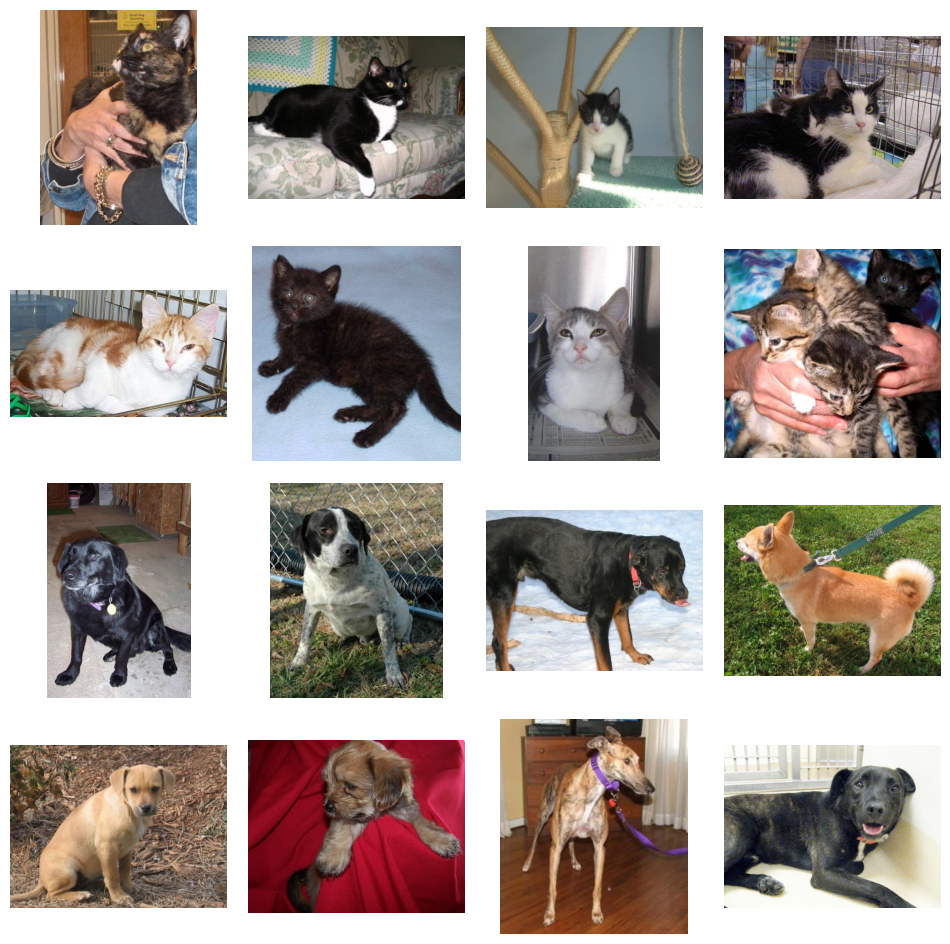

In [5]:
fig = plt.figure(figsize = (12, 12))
fig.subplots_adjust(hspace=0.1, wspace=0.1)
for i, element in enumerate(os.listdir(os.path.join(directories["train_Cat"]))[:8]):
    ax = fig.add_subplot(4, 4, i+1)
    img = Image.open(directories["train_Cat"]+element)
    ax.imshow(img)
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])

for i, element in enumerate(os.listdir(os.path.join(directories["train_Dog"]))[:8]):
    ax = fig.add_subplot(4, 4, i+9)
    img = Image.open(directories["train_Dog"]+element)
    ax.imshow(img)
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])

plt.show()

In [6]:
img_width, img_height = 150, 150
train_data_dir = 'dataset/train/'
validation_data_dir = 'dataset/valid/'
epochs = 1000
batch_size = 64
steps_per_epoch = train_size // batch_size
validation_steps = valid_size // batch_size
patience = 5
train_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)
train_generator = train_datagen.flow_from_directory(train_data_dir,
                                                    target_size=(img_height, img_width),
                                                    batch_size=batch_size, class_mode='binary')
validation_generator = test_datagen.flow_from_directory(validation_data_dir,
                                                        target_size=(img_height, img_width),
                                                        batch_size=batch_size, class_mode='binary')
train_datagen_augmentation = ImageDataGenerator(rescale=1./255,
                                   shear_range=0.2,
                                   zoom_range=0.2,
                                   rotation_range=30,
                                   horizontal_flip=True)
train_generator_augmentation = train_datagen_augmentation.flow_from_directory(train_data_dir,
                                                    target_size=(img_height, img_width),
                                                    batch_size=batch_size, class_mode='binary')

Found 17500 images belonging to 2 classes.
Found 4998 images belonging to 2 classes.
Found 17500 images belonging to 2 classes.


In [7]:
models = []
if not os.path.exists('history'):
    os.mkdir("history")
if not os.path.exists('charts'):
    os.mkdir("charts")

In [8]:
model_baseline=Sequential()
model_baseline.add(Input(shape=(150,150,3)))
model_baseline.add(Flatten())
model_baseline.add(Dense(units=1, activation='sigmoid'))
model_baseline.compile(loss='binary_crossentropy', optimizer=RMSprop(learning_rate=1e-4),metrics=['accuracy'])
model_baseline.summary()
models.append("baseline")                  


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 67500)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │        67,501 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67,501 (263.68 KB)

 Trainable params: 67,501 (263.68 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
es = EarlyStopping(patience=patience, monitor='val_accuracy', restore_best_weights=True)


In [10]:
history_baseline = model_baseline.fit(train_generator,
                                                steps_per_epoch=steps_per_epoch,
                                                epochs=epochs,
                                                validation_data=validation_generator,
                                                validation_steps=validation_steps,
                                                callbacks=[es])
history_baseline_df = pd.DataFrame(history_baseline.history)
history_baseline_csv_file = 'history/history_baseline.csv'

with open(history_baseline_csv_file, mode='w') as f:
    history_baseline_df.to_csv(f)


Epoch 1/1000


/Users/jtadych/Code/venv312/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


136/136 ━━━━━━━━━━━━━━━━━━━━ 9s 64ms/step - accuracy: 0.5029 - loss: 1.1212 - val_accuracy: 0.5028 - val_loss: 1.1268
Epoch 2/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 8s 61ms/step - accuracy: 0.5163 - loss: 0.9237 - val_accuracy: 0.4972 - val_loss: 1.0798
Epoch 3/1000
  1/136 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4844 - loss: 1.1951

/Users/jtadych/Code/venv312/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


136/136 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.4921 - loss: 1.2135 - val_accuracy: 0.4884 - val_loss: 0.9729
Epoch 4/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 8s 60ms/step - accuracy: 0.5427 - loss: 0.8790 - val_accuracy: 0.5044 - val_loss: 0.8192
Epoch 5/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 8s 58ms/step - accuracy: 0.5217 - loss: 0.9043 - val_accuracy: 0.4992 - val_loss: 1.4659
Epoch 6/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.5549 - loss: 0.9535 - val_accuracy: 0.5481 - val_loss: 0.7756
Epoch 7/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 7s 54ms/step - accuracy: 0.5289 - loss: 0.9074 - val_accuracy: 0.5509 - val_loss: 0.7313
Epoch 8/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 7s 55ms/step - accuracy: 0.5202 - loss: 0.9168 - val_accuracy: 0.5108 - val_loss: 0.8840
Epoch 9/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.4844 - loss: 0.9774 - val_accuracy: 0.5200 - val_loss: 1.0295
Epoch 10/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 7s 55ms/step - accuracy: 0.5371 - loss: 0.9064 - val_

In [11]:
def show():
    max_index = 0
    min_accuracy = 1
    max_loss = 0
    colors = plt.cm.rainbow(np.linspace(0, 1, len(models)))

    for model in models:
        df = pd.read_csv(f'history/history_{model}.csv', index_col=0)
        df.index += 1
        if max_index < max(df.index):
            max_index = max(df.index)
        if min_accuracy > min(df[['accuracy', 'val_accuracy']].min()):
            min_accuracy = min(df[['accuracy', 'val_accuracy']].min())
        if max_loss < max(df[['loss', 'val_loss']].max()):
            max_loss = max(df[['loss', 'val_loss']].max())

    for model in models:
        df = pd.read_csv(f'history/history_{model}.csv', index_col=0)
        df.index += 1
        fig = plt.figure(figsize=(16,12))
        ax = fig.add_subplot(211)
        ax.plot(df['accuracy'], "bp--")
        ax.plot(df['val_accuracy'], "rp--")
        ax.set_title(f'Model {model} Accuracy', fontsize=20)
        ax.set_ylabel('Accuracy', fontsize=15)
        ax.set_xlabel('Epoch', fontsize=15)
        ax.set_xlim([1, max_index])
        ax.set_ylim([min_accuracy, 1])

        for milestone in (0.7, 0.8, 0.9, 0.95):
            ax.axhline(milestone, color="k", linestyle="--")
            try:
                if min(df[df['val_accuracy'] >= milestone].index) > 1:
                    plt.axvline(min(df[df['val_accuracy'] >= milestone].index), color="g", linestyle="--")
                    ax.text(min(df[df['val_accuracy'] >= milestone].index)+0.6, min_accuracy+0.02,
                            f'Epoch: {min(df[df["val_accuracy"] >= milestone].index)}', rotation=90)
            except:
                pass

        plt.legend(['Training', 'Validation'], loc='lower right')
        ax = fig.add_subplot(212)
        ax.plot(df['loss'], "bp--")
        ax.plot(df['val_loss'], "rp--")
        ax.set_title(f'Model {model} Loss', fontsize=20)
        ax.set_ylabel('Loss', fontsize=15)
        ax.set_xlabel('Epoch', fontsize=15)
        ax.set_xlim([1, max_index])
        ax.set_ylim([0, max_loss])
        ax.legend(['Training', 'Validation'], loc='upper right')
        plt.tight_layout()
        plt.savefig(f'charts/train_history_{model}.png', transparent=True, dpi=600)
        plt.show()

    fig = plt.figure(figsize=(16,12))
    ax = fig.add_subplot(211)
    for model, color in zip(models, colors):
        df = pd.read_csv(f'history/history_{model}.csv', index_col=0)
        df.index += 1
        ax.plot(df['val_accuracy'], label=f'Model {model}', color=color, linewidth=3)
        ax.axhline(df['val_accuracy'].max(), color=color, linestyle="dotted", linewidth=4)

    ax.set_title(f'Accuracy', fontsize=20)
    ax.set_ylabel('Accuracy', fontsize=15)
    ax.set_xlabel('Epoch', fontsize=15)
    ax.set_xlim([1, max_index])
    ax.set_ylim([min_accuracy, 1])
    for milestone in (0.7, 0.8, 0.9, 0.95):
        ax.axhline(milestone, color="k", linestyle="--")
    plt.legend(loc='lower right')
    ax = fig.add_subplot(212)
    for model, color in zip(models, colors):
        df = pd.read_csv(f'history/history_{model}.csv', index_col=0)
        df.index += 1
        ax.plot(df['val_loss'], label=f'Model {model}', color=color, linewidth=3)
        ax.axhline(df['val_loss'].min(), color=color, linestyle="dotted", linewidth=4)
    ax.set_title(f'Loss', fontsize=20)
    ax.set_ylabel('Loss', fontsize=15)
    ax.set_xlabel('Epoch', fontsize=15)
    ax.set_xlim([1, max_index])
    ax.set_ylim([0, max_loss])
    ax.legend(loc='upper right')
    plt.tight_layout()
    plt.savefig(f'charts/train_history_of_each_model.png', transparent=True, dpi=600)
    plt.show()

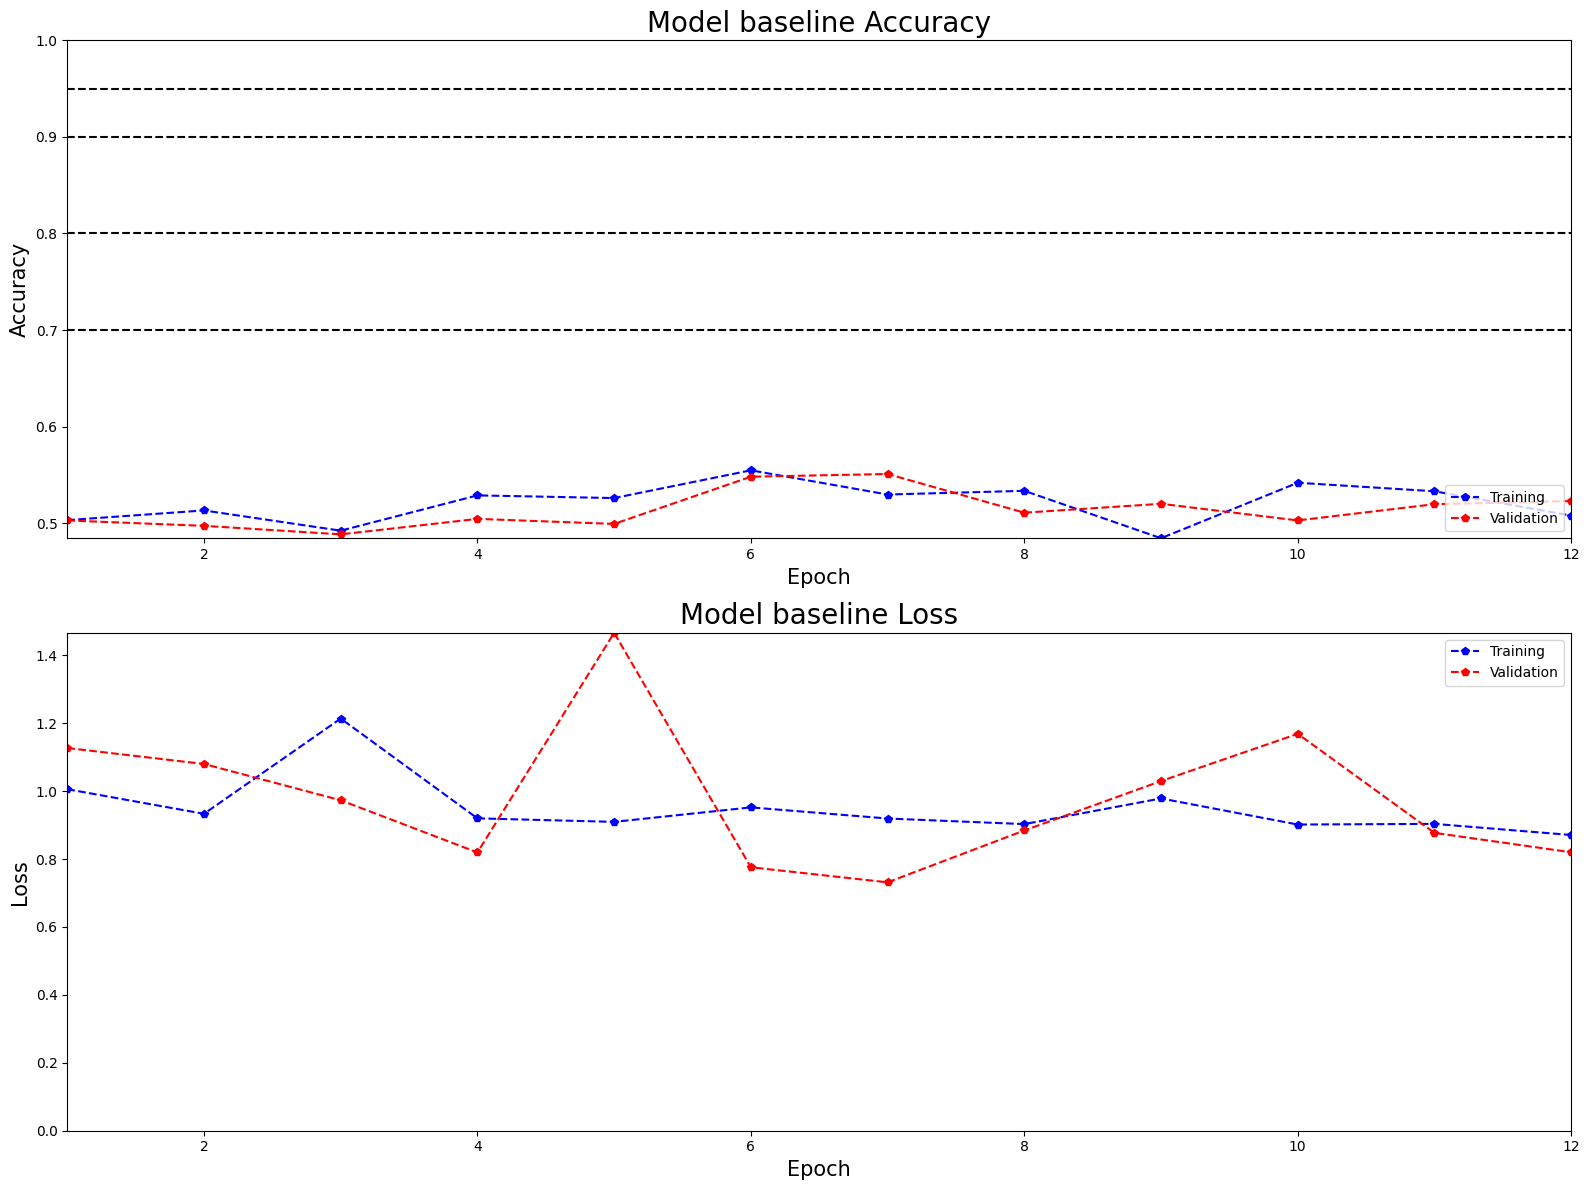

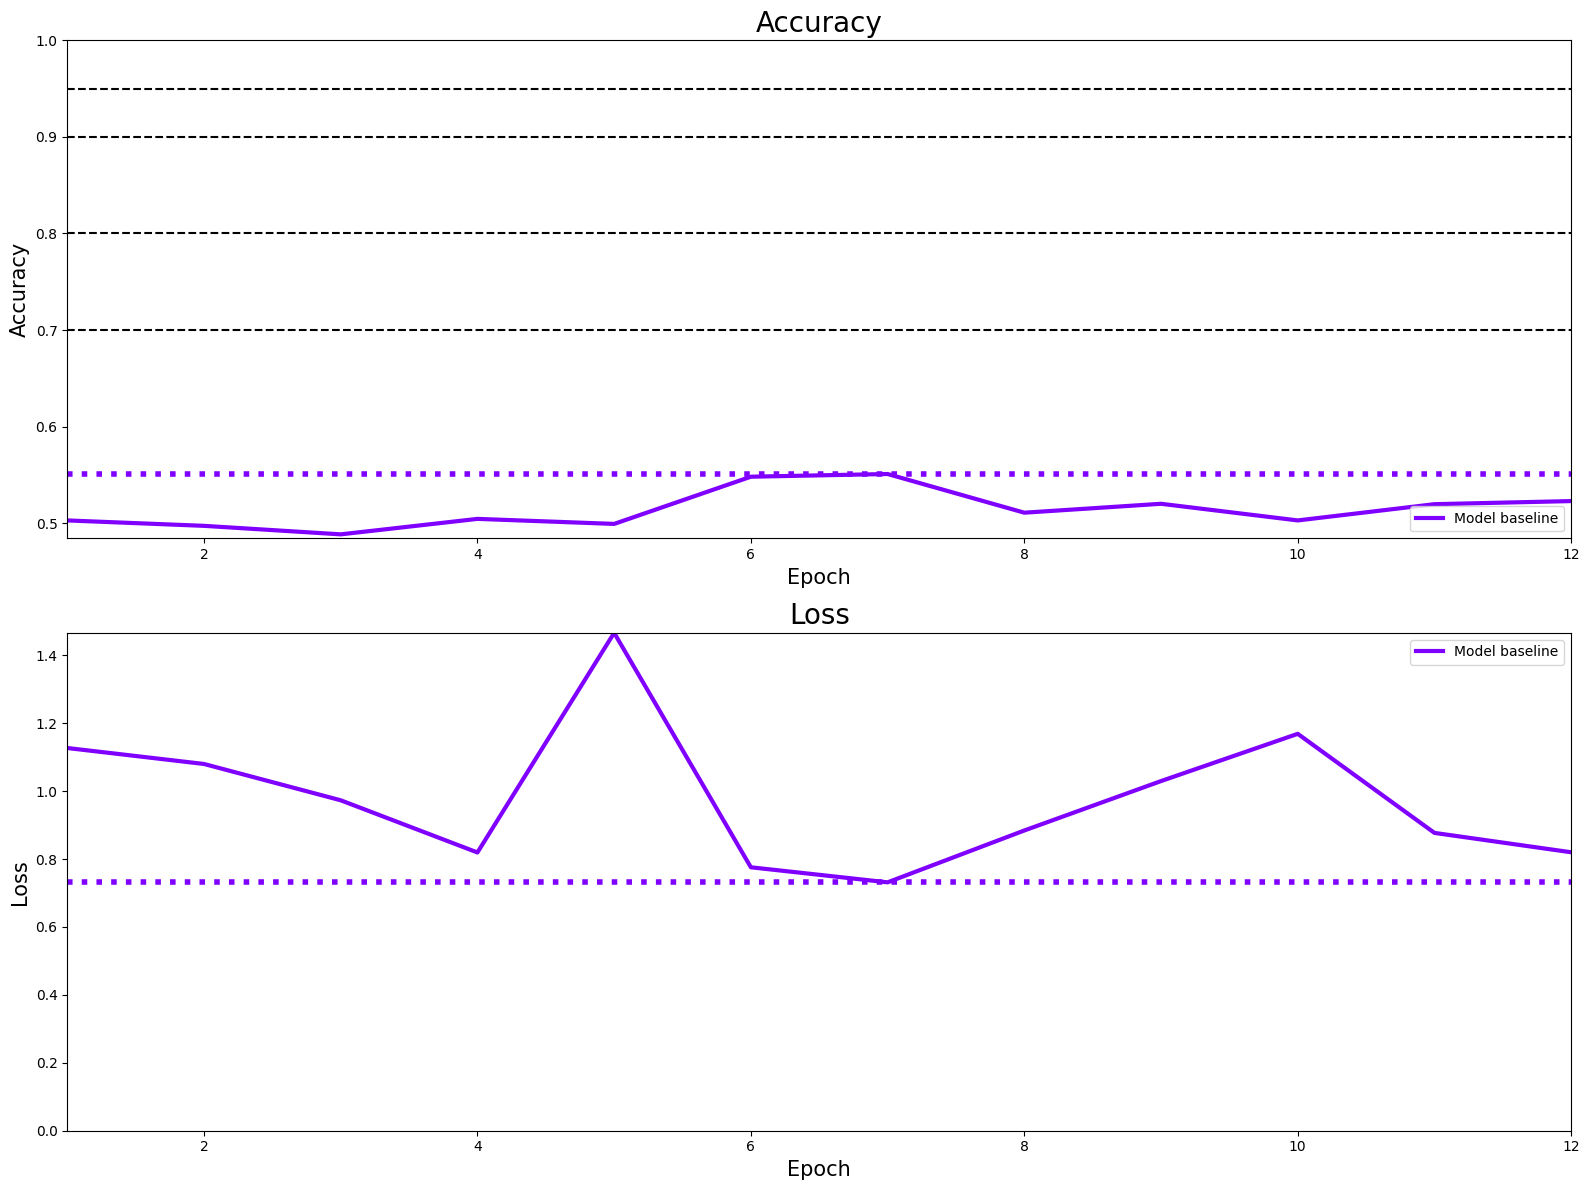

In [12]:
show()

# Model podstawowy 1

In [13]:
model_simple_1 = Sequential()
model_simple_1.add(Input(shape=(150,150,3)))
model_simple_1.add(Conv2D(filters=10, kernel_size=(3, 3), activation='relu'))
model_simple_1.add(MaxPooling2D(2, 2))
model_simple_1.add(Flatten())
model_simple_1.add(Dense(units=1, activation='sigmoid'))
model_simple_1.compile(loss='binary_crossentropy',
                       optimizer='adam',
                       metrics=['accuracy'])
model_simple_1.summary()
models.append("simple_1")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 10)   │           280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 54760)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │        54,761 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,041 (215.00 KB)

 Trainable params: 55,041 (215.00 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
history_simple_1 = model_simple_1.fit(train_generator,
                                                steps_per_epoch=steps_per_epoch,
                                                epochs=epochs,
                                                validation_data=validation_generator,
                                                validation_steps=validation_steps,
                                                callbacks=[es])

history_simple_1_df = pd.DataFrame(history_simple_1.history)
history_simple_1_csv_file = 'history/history_simple_1.csv'

with open(history_simple_1_csv_file, mode='w') as f:
    history_simple_1_df.to_csv(f)

Epoch 1/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 10s 70ms/step - accuracy: 0.5341 - loss: 0.9758 - val_accuracy: 0.6234 - val_loss: 0.6405
Epoch 2/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.6692 - loss: 0.6011

/Users/jtadych/Code/venv312/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


136/136 ━━━━━━━━━━━━━━━━━━━━ 9s 68ms/step - accuracy: 0.6693 - loss: 0.6011 - val_accuracy: 0.6971 - val_loss: 0.5679
Epoch 3/1000
  2/136 ━━━━━━━━━━━━━━━━━━━━ 7s 53ms/step - accuracy: 0.7070 - loss: 0.5564

/Users/jtadych/Code/venv312/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


136/136 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.7263 - loss: 0.5403 - val_accuracy: 0.7027 - val_loss: 0.5712
Epoch 4/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 10s 73ms/step - accuracy: 0.7184 - loss: 0.5457 - val_accuracy: 0.7332 - val_loss: 0.5444
Epoch 5/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 9s 69ms/step - accuracy: 0.7572 - loss: 0.5000 - val_accuracy: 0.7288 - val_loss: 0.5507
Epoch 6/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.8261 - loss: 0.4509 - val_accuracy: 0.7280 - val_loss: 0.5435
Epoch 7/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 9s 69ms/step - accuracy: 0.7801 - loss: 0.4635 - val_accuracy: 0.7015 - val_loss: 0.5750
Epoch 8/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 9s 67ms/step - accuracy: 0.7946 - loss: 0.4392 - val_accuracy: 0.7372 - val_loss: 0.5452
Epoch 9/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.7809 - loss: 0.4338 - val_accuracy: 0.7244 - val_loss: 0.5730
Epoch 10/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 9s 68ms/step - accuracy: 0.8158 - loss: 0.4150 - val

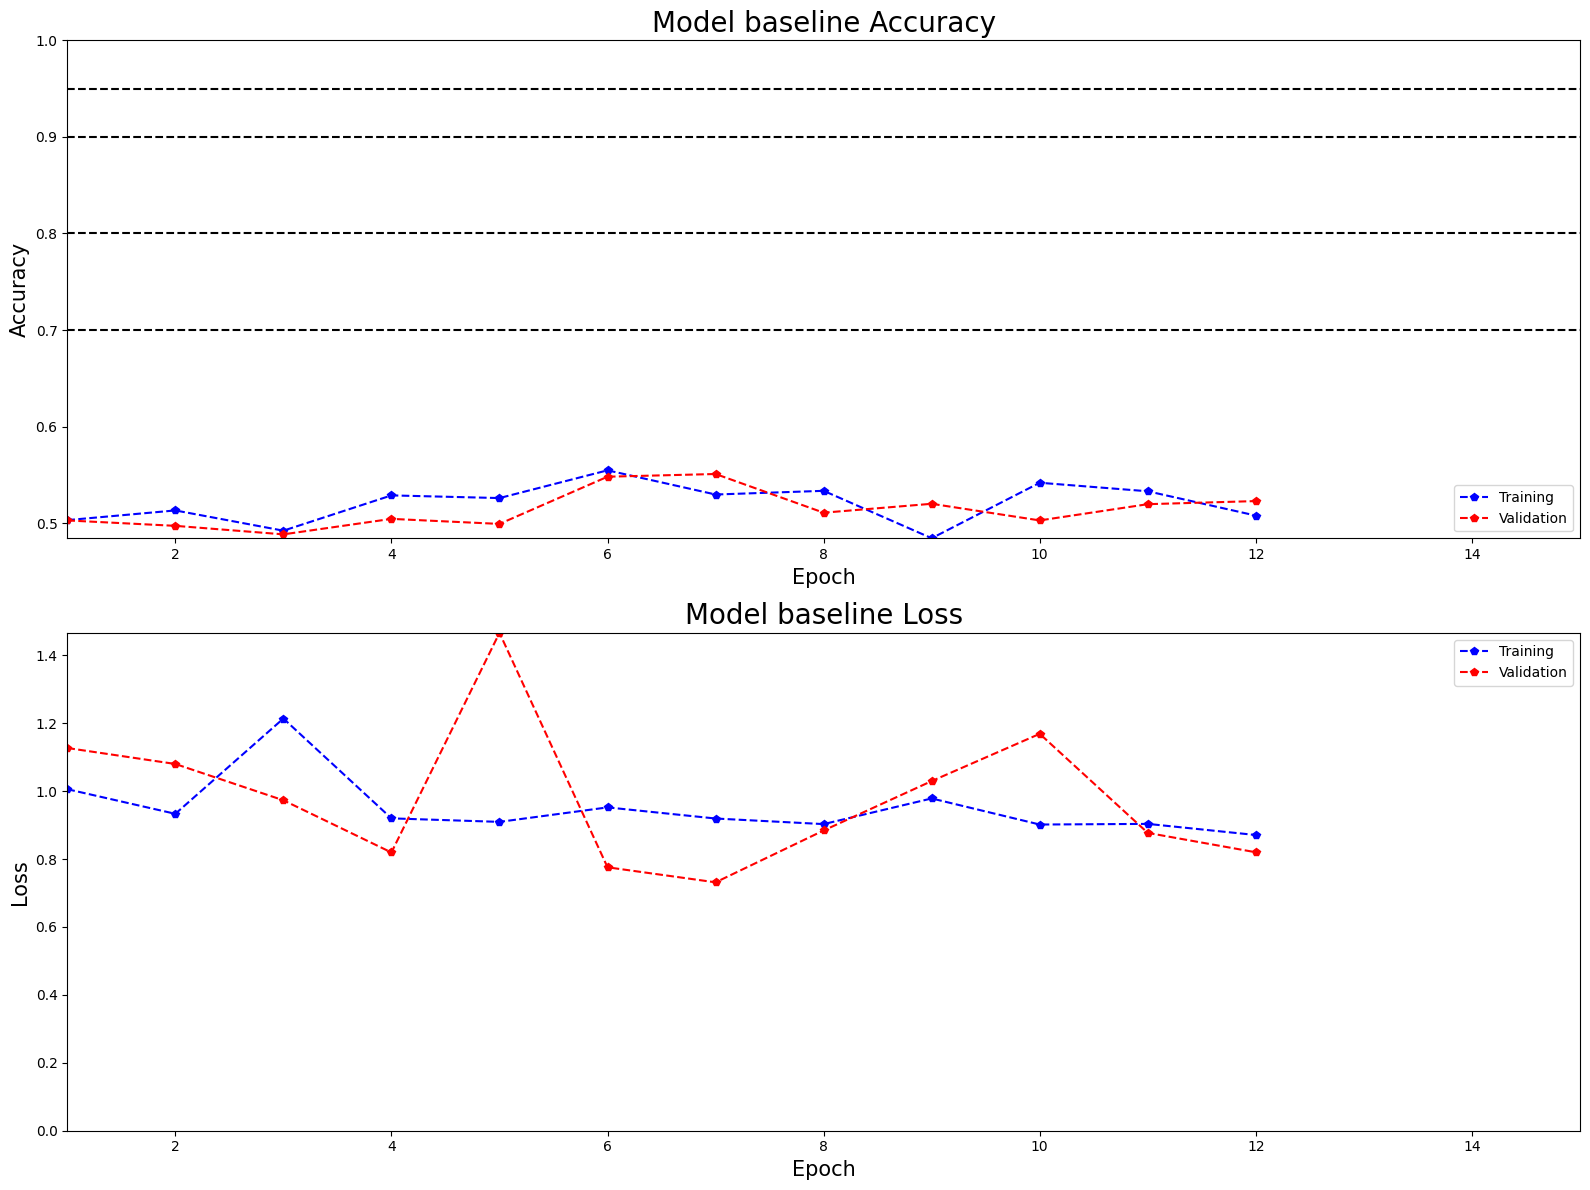

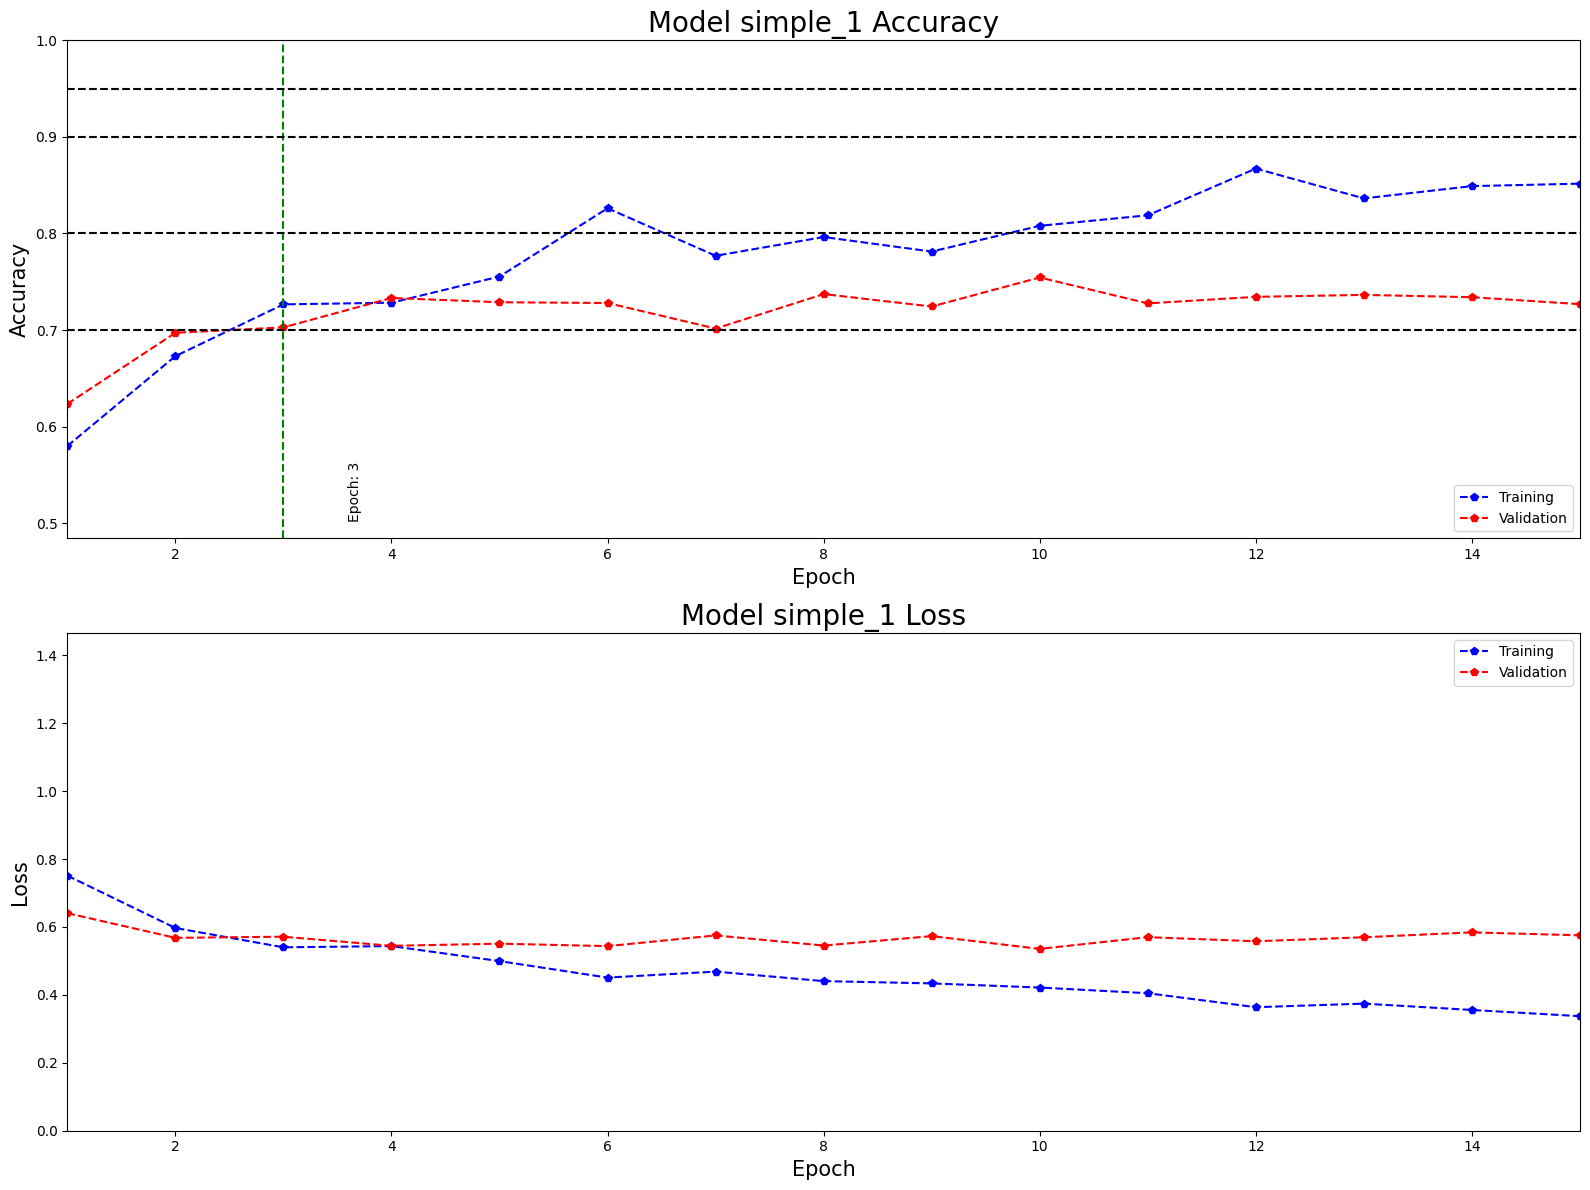

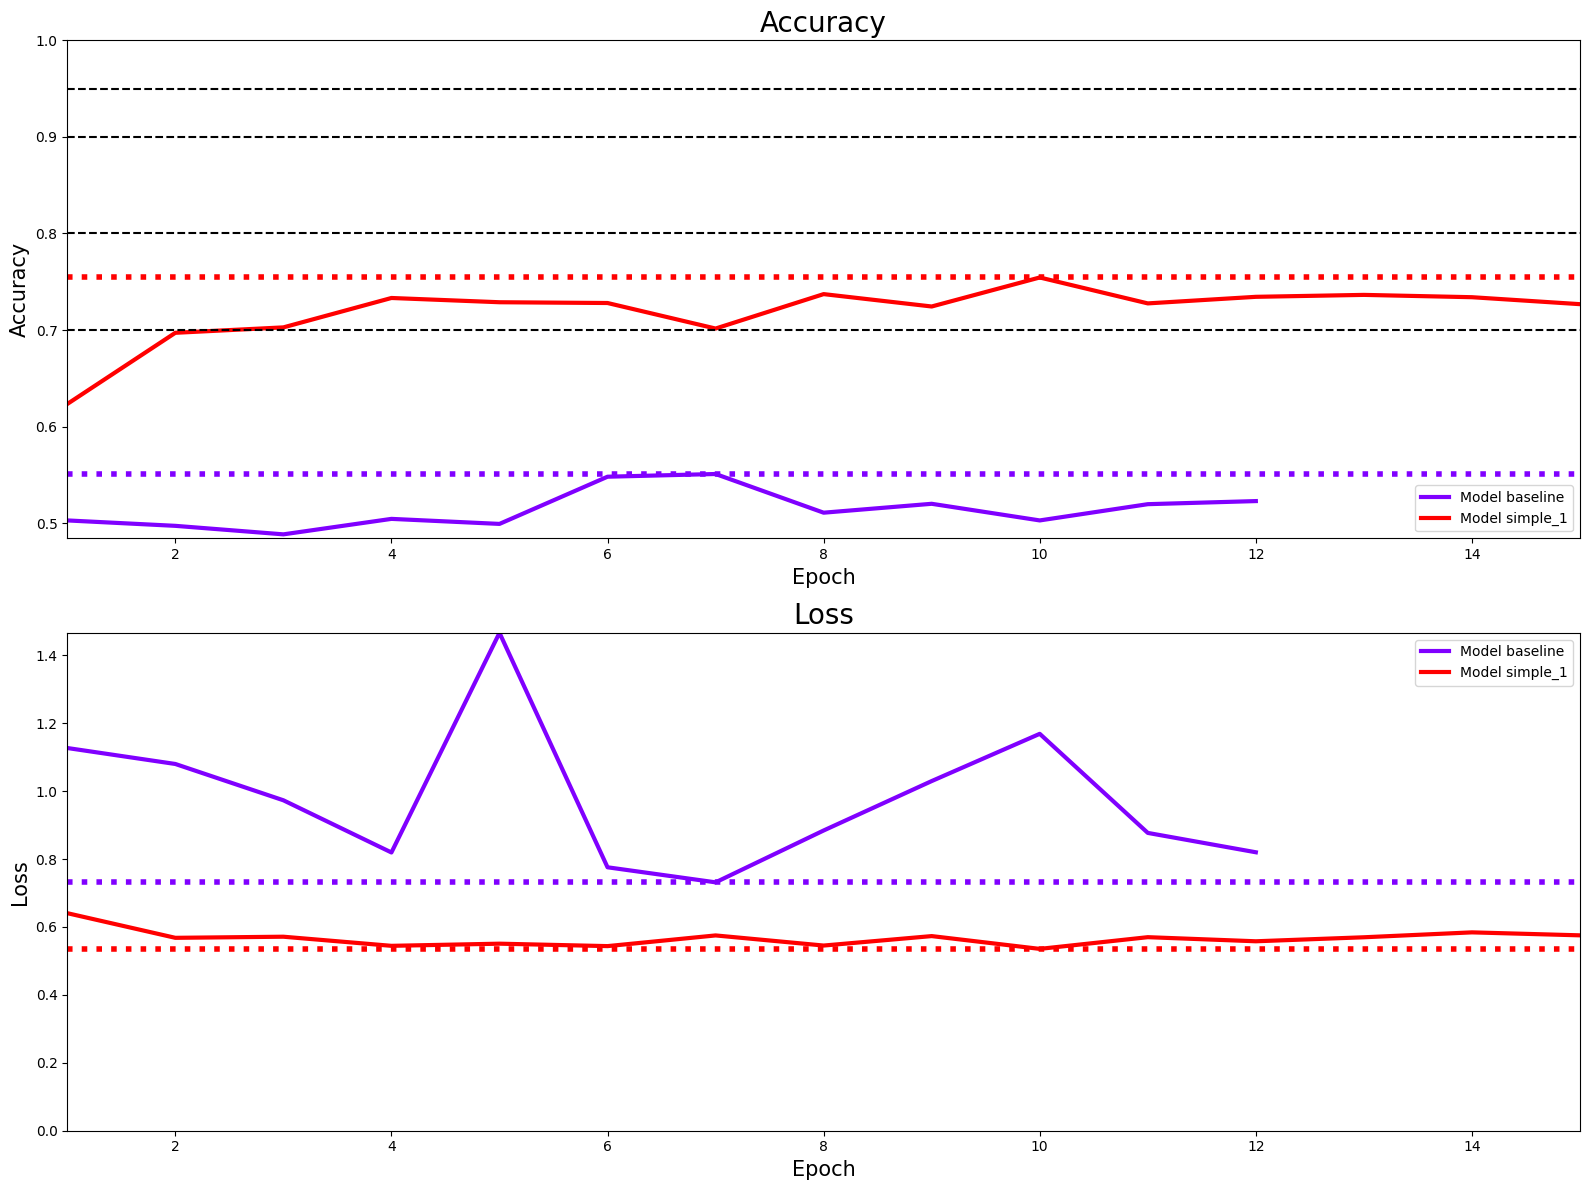

In [15]:
show()

In [16]:
model_simple_2 = Sequential()
model_simple_2.add(Input(shape=(150,150,3)))
model_simple_2.add(Conv2D(filters=10, kernel_size=(3, 3), padding='same', activation='relu'))
model_simple_2.add(MaxPooling2D(2, 2))
model_simple_2.add(Flatten())
model_simple_2.add(Dense(units=1, activation='sigmoid'))
model_simple_2.compile(loss='binary_crossentropy',
                       optimizer='adam',
                       metrics=['accuracy'])
model_simple_2.summary()
models.append("simple_2")

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 150, 150, 10)   │           280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 75, 75, 10)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 56250)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │        56,251 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,531 (220.82 KB)

 Trainable params: 56,531 (220.82 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
history_simple_2 = model_simple_2.fit(train_generator,
                                                steps_per_epoch=steps_per_epoch,
                                                epochs=epochs,
                                                validation_data=validation_generator,
                                                validation_steps=validation_steps,
                                                callbacks=[es])

history_simple_2_df = pd.DataFrame(history_simple_2.history)
history_simple_2_csv_file = 'history/history_simple_2.csv'

with open(history_simple_2_csv_file, mode='w') as f:
    history_simple_2_df.to_csv(f)

Epoch 1/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 10s 68ms/step - accuracy: 0.5470 - loss: 0.8254 - val_accuracy: 0.6186 - val_loss: 0.6578
Epoch 2/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 9s 69ms/step - accuracy: 0.6662 - loss: 0.6220 - val_accuracy: 0.6987 - val_loss: 0.5927
Epoch 3/1000
  1/136 ━━━━━━━━━━━━━━━━━━━━ 7s 54ms/step - accuracy: 0.7344 - loss: 0.5605

/Users/jtadych/Code/venv312/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


  2/136 ━━━━━━━━━━━━━━━━━━━━ 7s 54ms/step - accuracy: 0.7148 - loss: 0.5640

/Users/jtadych/Code/venv312/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


136/136 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.6956 - loss: 0.5674 - val_accuracy: 0.6983 - val_loss: 0.5895
Epoch 4/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 10s 71ms/step - accuracy: 0.7076 - loss: 0.5728 - val_accuracy: 0.7115 - val_loss: 0.5711
Epoch 5/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 11s 82ms/step - accuracy: 0.7449 - loss: 0.5236 - val_accuracy: 0.7087 - val_loss: 0.5835
Epoch 6/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.7424 - loss: 0.5247 - val_accuracy: 0.7111 - val_loss: 0.5663
Epoch 7/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 11s 81ms/step - accuracy: 0.7541 - loss: 0.5076 - val_accuracy: 0.6831 - val_loss: 0.5967
Epoch 8/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 10s 76ms/step - accuracy: 0.7847 - loss: 0.4662 - val_accuracy: 0.7171 - val_loss: 0.5749
Epoch 9/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.7426 - loss: 0.4532 - val_accuracy: 0.7392 - val_loss: 0.5382
Epoch 10/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 10s 73ms/step - accuracy: 0.7836 - loss: 0.4604 -

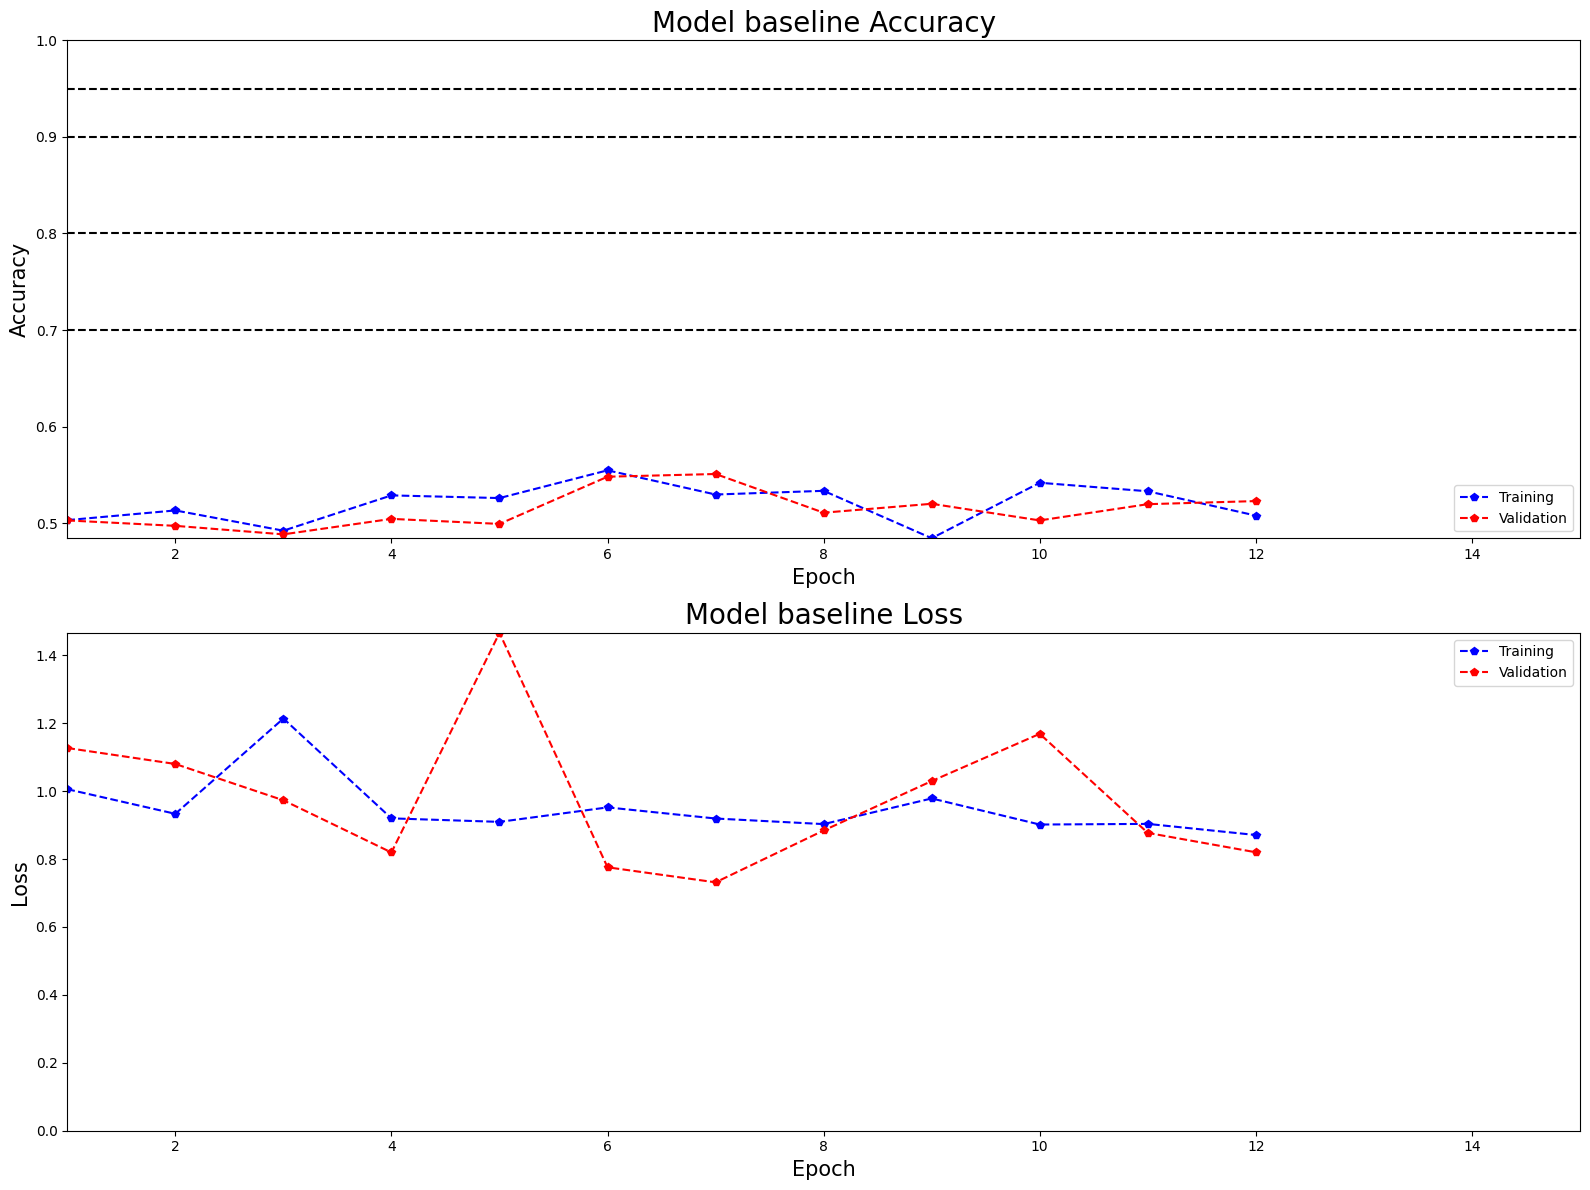

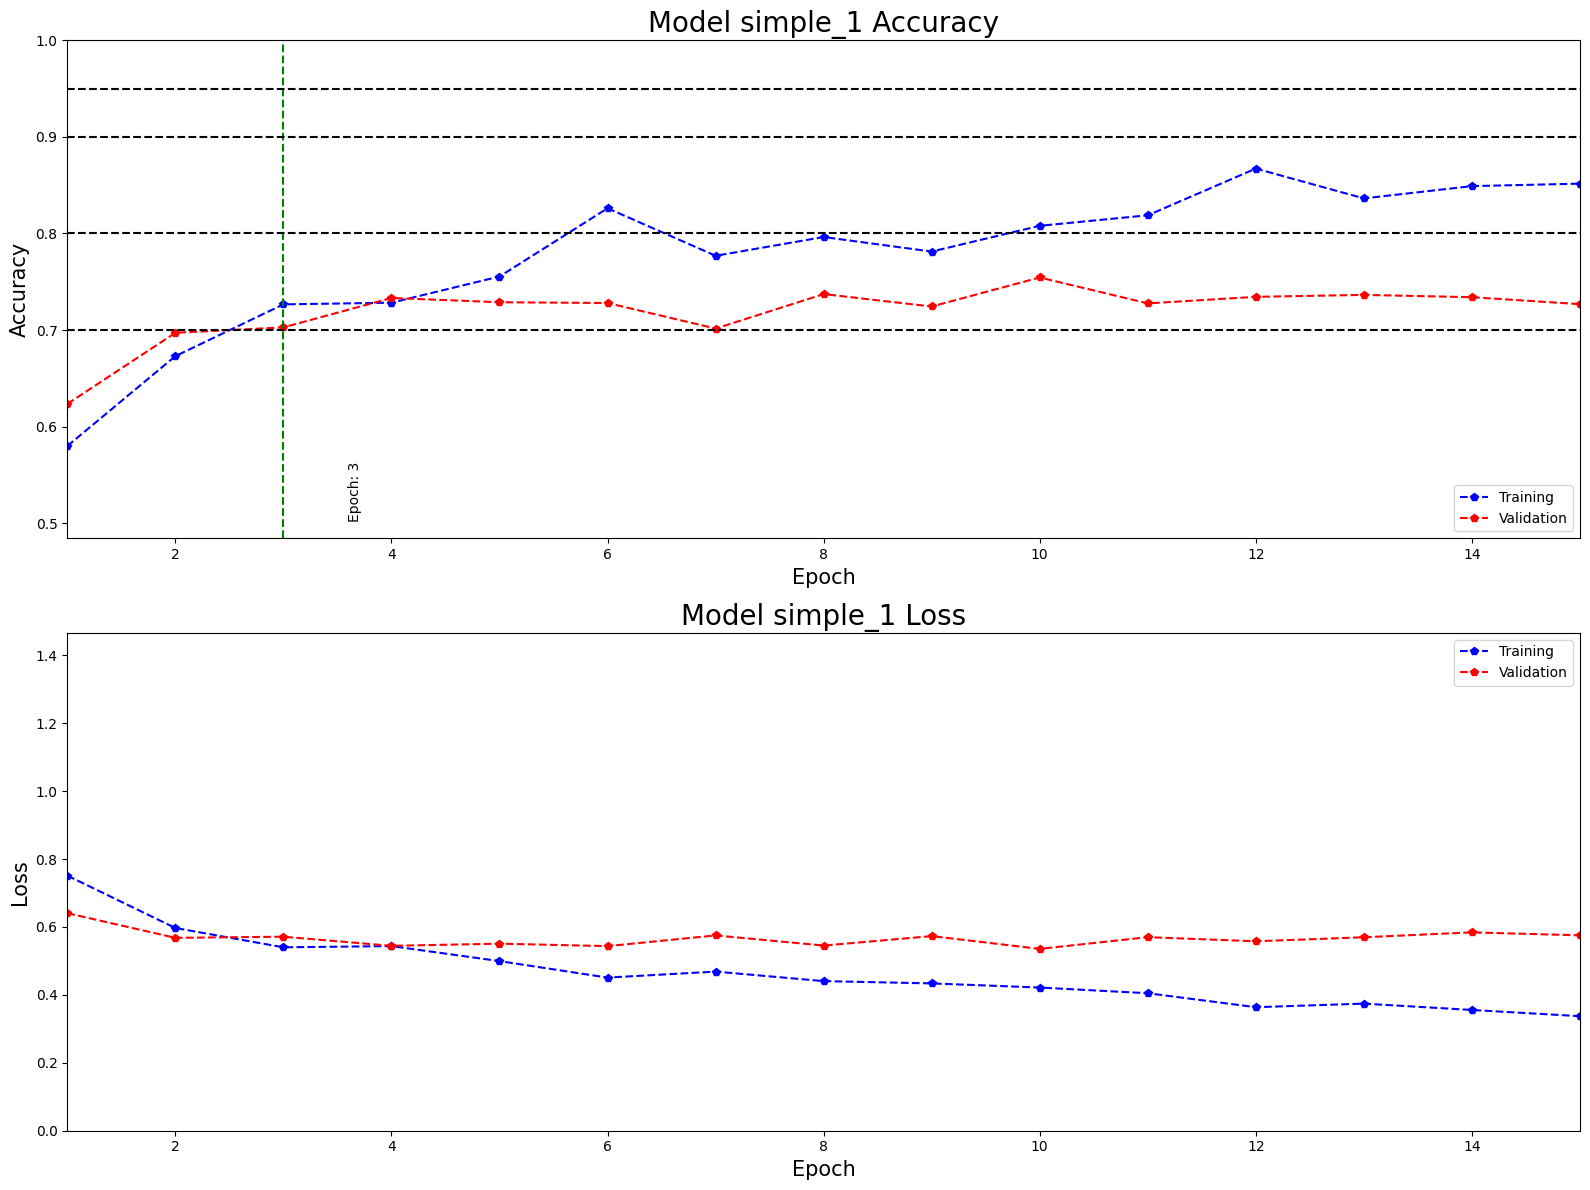

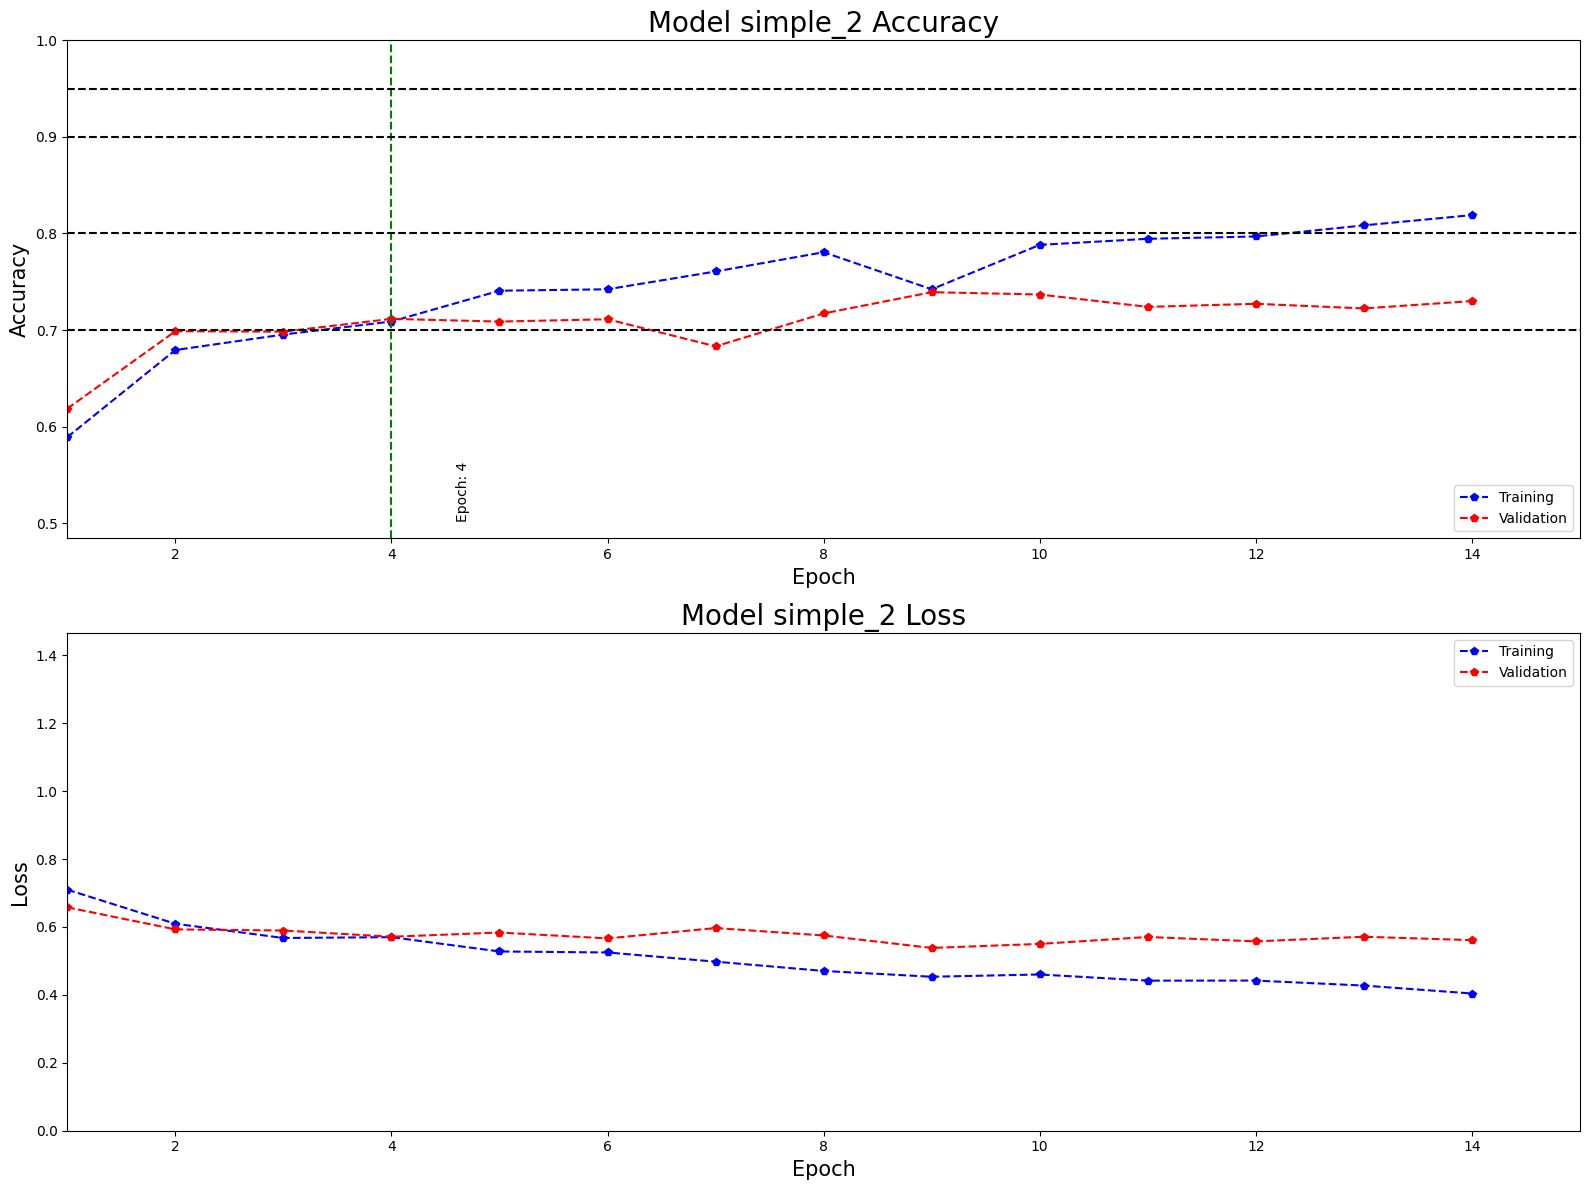

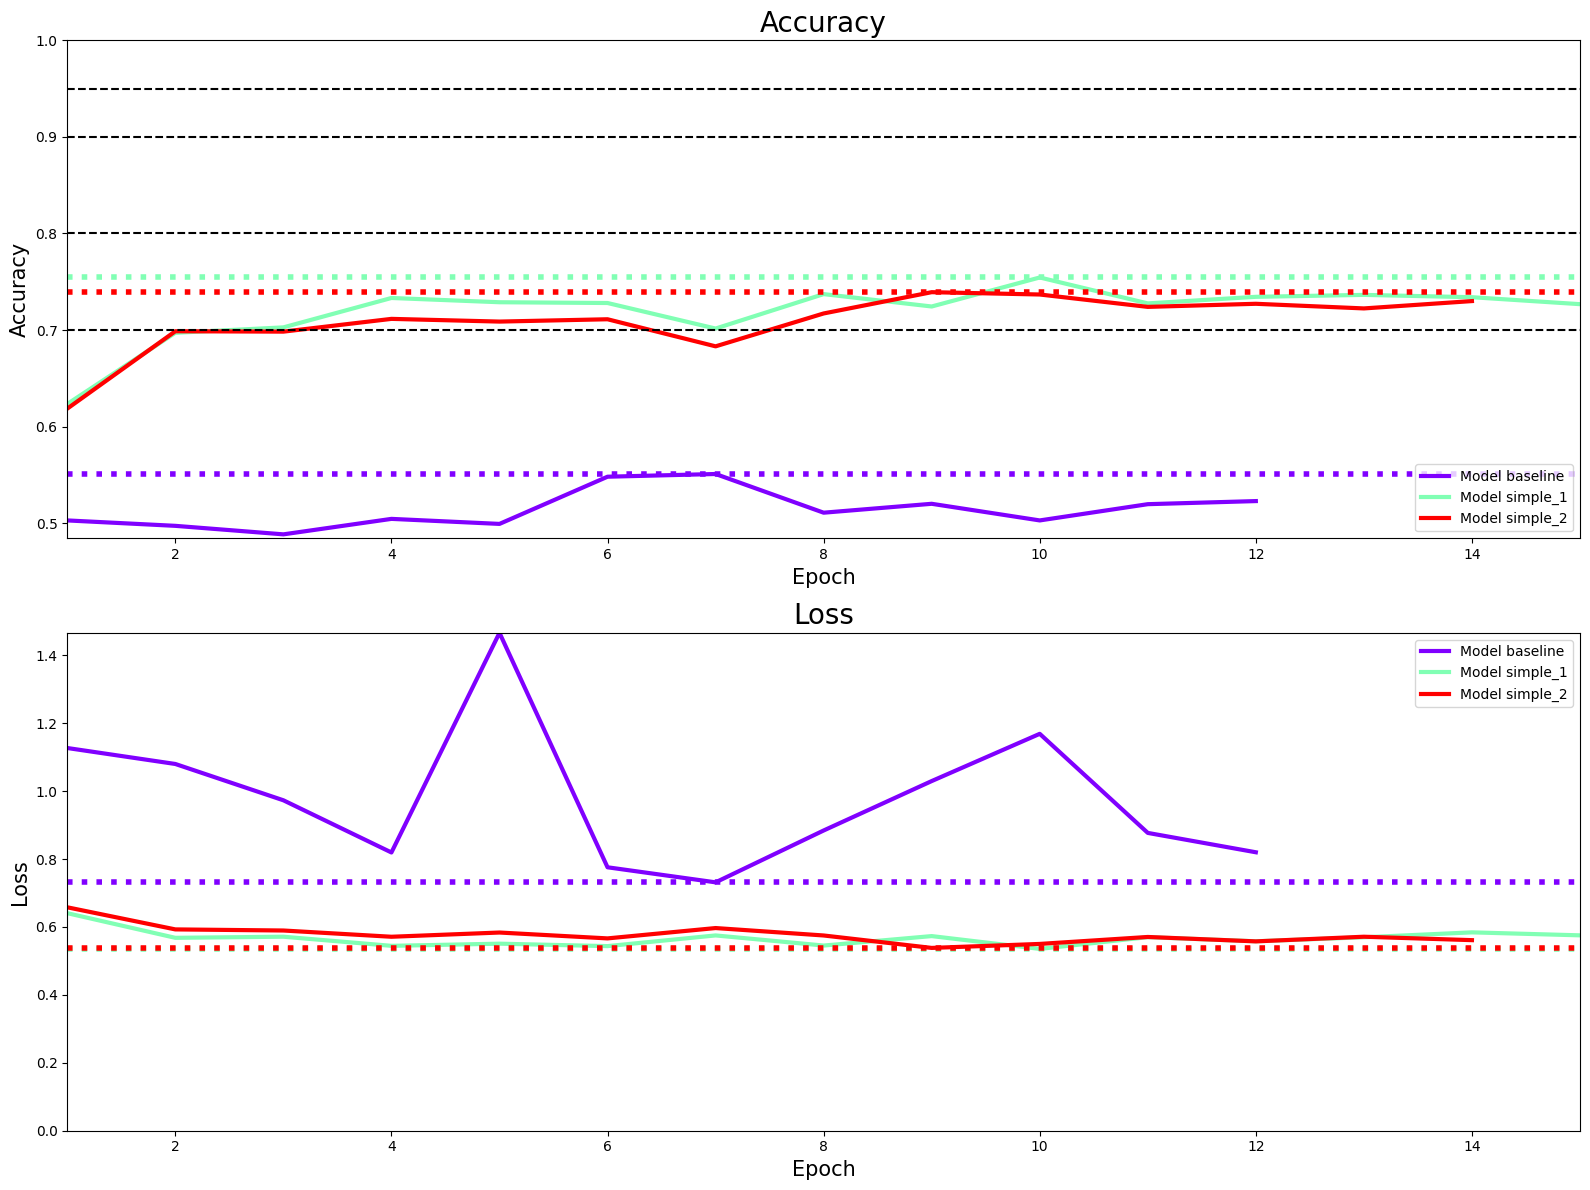

In [18]:
show()

## Model 1

In [20]:
model_1 = Sequential()

model_1.add(Input(shape=(150,150,3)))
# Block 1
model_1.add(Conv2D(filters=16, kernel_size=(3, 3), activation='relu', padding='same'))
model_1.add(Conv2D(filters=16, kernel_size=(3, 3), activation='relu', padding='same'))
model_1.add(MaxPooling2D(pool_size=(2, 2)))

# Block 2
model_1.add(Conv2D(filters=32, kernel_size=(3, 3), activation='relu', padding='same'))
model_1.add(Conv2D(filters=32, kernel_size=(3, 3), activation='relu', padding='same'))
model_1.add(MaxPooling2D(pool_size=(2, 2)))

# Block 3
model_1.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu', padding='same'))
model_1.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu', padding='same'))
model_1.add(MaxPooling2D(pool_size=(2, 2)))

# Block 4
model_1.add(Conv2D(filters=128, kernel_size=(3, 3), activation='relu', padding='same'))
model_1.add(Conv2D(filters=128, kernel_size=(3, 3), activation='relu', padding='same'))
model_1.add(MaxPooling2D(pool_size=(2, 2)))
model_1.add(Flatten())
model_1.add(Dense(256, activation='relu'))
model_1.add(Dense(128, activation='relu'))
model_1.add(Dense(units=1, activation='sigmoid'))
model_1.compile(loss='binary_crossentropy',
                       optimizer=RMSprop(learning_rate=1e-4),
                       metrics=['accuracy'])
model_1.summary()
models.append("model_1")

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 150, 150, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 150, 150, 16)   │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 75, 75, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 75, 75, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 75, 75, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 37, 37, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 37, 37, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 37, 37, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 18, 18, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 18, 18, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 18, 18, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 10368)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │     2,654,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,981,009 (11.37 MB)

 Trainable params: 2,981,009 (11.37 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
history_model_1 = model_1.fit(train_generator,
                                                steps_per_epoch=steps_per_epoch,
                                                epochs=epochs,
                                                validation_data=validation_generator,
                                                validation_steps=validation_steps,
                                                callbacks=[es])

history_model_1 = pd.DataFrame(history_simple_1.history)
history_model_1 = 'history/history_model_1.csv'

with open(history_simple_1_csv_file, mode='w') as f:
    history_simple_1_df.to_csv(f)

Epoch 1/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 64s 472ms/step - accuracy: 0.8328 - loss: 0.3711 - val_accuracy: 0.8141 - val_loss: 0.4140
Epoch 2/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 64s 474ms/step - accuracy: 0.8390 - loss: 0.3702 - val_accuracy: 0.8233 - val_loss: 0.3904
Epoch 3/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - accuracy: 0.8516 - loss: 0.3373 - val_accuracy: 0.8157 - val_loss: 0.4109
Epoch 4/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 64s 468ms/step - accuracy: 0.8443 - loss: 0.3551 - val_accuracy: 0.8233 - val_loss: 0.4007
Epoch 5/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 64s 470ms/step - accuracy: 0.8453 - loss: 0.3443 - val_accuracy: 0.8145 - val_loss: 0.4101
Epoch 6/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - accuracy: 0.8436 - loss: 0.3664 - val_accuracy: 0.8277 - val_loss: 0.3835
Epoch 7/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 519s 4s/step - accuracy: 0.8548 - loss: 0.3285 - val_accuracy: 0.8305 - val_loss: 0.3834
Epoch 8/1000
136/136 ━━━━━━━━━━━━━━━━━━━━ 65s 476ms/step - accuracy: 0.8620

In [24]:
show()

FileNotFoundError: [Errno 2] No such file or directory: 'history/history_model_1.csv'

## Model 2

In [ ]:
model_2 = Sequential()
model_2.add(Input(shape=(150,150,3)))
# Block 1
model_2.add(Conv2D(filters=16, kernel_size=(3, 3), activation='relu', padding='same'))
model_2.add(Conv2D(filters=16, kernel_size=(3, 3), activation='relu', padding='same'))
model_2.add(MaxPooling2D(pool_size=(2, 2)))

# Block 2
model_2.add(Conv2D(filters=32, kernel_size=(3, 3), activation='relu', padding='same'))
model_2.add(Conv2D(filters=32, kernel_size=(3, 3), activation='relu', padding='same'))
model_2.add(MaxPooling2D(pool_size=(2, 2)))

# Block 3
model_2.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu', padding='same'))
model_2.add(Conv2D(filters=64, kernel_size=(3, 3), activation='relu', padding='same'))
model_2.add(MaxPooling2D(pool_size=(2, 2)))

# Block 4
model_2.add(Conv2D(filters=128, kernel_size=(3, 3), activation='relu', padding='same'))
model_2.add(Conv2D(filters=128, kernel_size=(3, 3), activation='relu', padding='same'))
model_2.add(MaxPooling2D(pool_size=(2, 2)))
model_2.add(Flatten())
model_2.add(Dropout(0.5))
model_2.add(Dense(256, activation='relu'))
model_2.add(Dropout(0.5))
model_2.add(Dense(128, activation='relu'))
model_2.add(Dense(units=1, activation='sigmoid'))
model_2.compile(loss='binary_crossentropy',
                       optimizer=RMSprop(learning_rate=1e-4),
                       metrics=['accuracy'])
model_2.summary()
models.append("model_2")